## QUESTION# 01

In [1]:
# Importing the required library for Google Drive
from google.colab import drive

# Mounting Google Drive to access the files
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Importing necessary libraries
import pandas as pd
import zipfile
import os

# Path to the uploaded zip file on Google Drive
zip_file_path = '/content/drive/MyDrive/Lab_13_AI_DataSet/Lab_13_DataSet_1_AI.zip'

# Unzipping the file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall('/content/drive/MyDrive/Lab_13_AI_DataSet/')

# Now, load the dataset from the extracted file
file_path = '/content/drive/MyDrive/Lab_13_AI_DataSet/Purchase_new.csv'

# Loading the dataset into a Pandas DataFrame
df = pd.read_csv(file_path)

# Display the first few rows of the dataset
df.head()

,Holiday,Discount,Free Delivery,Purchase
0,No,Yes,Yes,Yes
1,No,Yes,Yes,Yes
2,No,No,No,No
3,yes,Yes,Yes,Yes
4,yes,Yes,Yes,Yes


In [5]:
# Importing necessary libraries
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Load the dataset (assuming it's already done)
# df = pd.read_csv('your_file_path.csv')

# Identifying categorical and numerical features
categorical_features = df.select_dtypes(include=['object']).columns  # Select columns with object type (strings)
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns  # Select columns with numerical types

# Display the identified features
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

# Checking for missing values
missing_values = df.isnull().sum()
print("\nMissing Values:\n", missing_values)

# Handling missing values
# If missing values are found in categorical columns, we can fill them with the mode (most frequent value)
# For numerical columns, we can fill with the median
for col in categorical_features:
    # Fill missing categorical values with mode
    df[col] = df[col].fillna(df[col].mode()[0])

for col in numerical_features:
    # Fill missing numerical values with median
    df[col] = df[col].fillna(df[col].median())

# Check again if any missing values remain
missing_values_after = df.isnull().sum()
print("\nMissing Values After Handling:\n", missing_values_after)

# Encoding categorical features (Holiday, Discount, Free Delivery, Purchase)
encoder = LabelEncoder()

df['Holiday'] = encoder.fit_transform(df['Holiday'])  # 0 for 'No', 1 for 'Yes'
df['Discount'] = encoder.fit_transform(df['Discount'])  # 0 for 'No', 1 for 'Yes'
df['Free Delivery'] = encoder.fit_transform(df['Free Delivery'])  # 0 for 'No', 1 for 'Yes'
df['Purchase'] = encoder.fit_transform(df['Purchase'])  # 0 for 'No', 1 for 'Yes'

# Display the first few rows after preprocessing and encoding
print("\nData after Preprocessing:\n", df.head())

Categorical Features: Index([], dtype='object')
Numerical Features: Index(['Holiday', 'Discount', 'Free Delivery', 'Purchase'], dtype='object')

Missing Values:
 Holiday          0
Discount         0
Free Delivery    0
Purchase         0
dtype: int64

Missing Values After Handling:
 Holiday          0
Discount         0
Free Delivery    0
Purchase         0
dtype: int64

Data after Preprocessing:
    Holiday  Discount  Free Delivery  Purchase
0        0         1              1         1
1        0         1              1         1
2        0         0              0         0
3        1         1              1         1
4        1         1              1         1


In [6]:
# Importing train_test_split from sklearn to split the data
from sklearn.model_selection import train_test_split

# Defining the input features (X) and the target variable (y)
X = df.drop('Purchase', axis=1)  # Drop the target variable 'Purchase' from input features
y = df['Purchase']  # The target variable is 'Purchase'

# Splitting the data into training and testing sets (70:30 ratio)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Display the shapes of the resulting datasets
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (21, 3)
Testing set size: (9, 3)


In [8]:
# Importing necessary libraries for evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Evaluate the Gini model
y_pred_gini = gini_classifier.predict(X_test)  # Predict using the Gini model

# Calculate and display the confusion matrix for the Gini model
conf_matrix_gini = confusion_matrix(y_test, y_pred_gini)
print("Confusion Matrix for Gini Model:")
print(conf_matrix_gini)

# The confusion matrix is a 2x2 matrix with the following structure:
# [[TN, FP],
#  [FN, TP]]
#
# Here, TN = True Negative, FP = False Positive, FN = False Negative, TP = True Positive

# Detailed explanation of the confusion matrix:
# 1. True Negative (TN) [conf_matrix_gini[0, 0]]:
#    - The count of instances where the actual class is "No (0)" and the model correctly predicted "No (0)".
#    - These are the instances where the model made the correct decision for "No".
#
# 2. False Positive (FP) [conf_matrix_gini[0, 1]]:
#    - The count of instances where the actual class is "No (0)" but the model incorrectly predicted "Yes (1)".
#    - These are the instances where the model falsely predicted "Yes" when it should have predicted "No".
#
# 3. False Negative (FN) [conf_matrix_gini[1, 0]]:
#    - The count of instances where the actual class is "Yes (1)" but the model incorrectly predicted "No (0)".
#    - These are the instances where the model failed to identify the "Yes" class.
#
# 4. True Positive (TP) [conf_matrix_gini[1, 1]]:
#    - The count of instances where the actual class is "Yes (1)" and the model correctly predicted "Yes (1)".
#    - These are the instances where the model made the correct decision for "Yes".

# Display the evaluation metrics for the Gini model
print("Accuracy:", accuracy_score(y_test, y_pred_gini))
print("Precision:", precision_score(y_test, y_pred_gini))
print("Recall:", recall_score(y_test, y_pred_gini))
print("Confusion Matrix:\n", conf_matrix_gini)

# Similarly, evaluating the Entropy model
y_pred_entropy = entropy_classifier.predict(X_test)  # Predict using the Entropy model

# Calculate and display the confusion matrix for the Entropy model
conf_matrix_entropy = confusion_matrix(y_test, y_pred_entropy)
print("\nConfusion Matrix for Entropy Model:")
print(conf_matrix_entropy)

# Detailed explanation for the confusion matrix of the Entropy model:
# 1. True Negative (TN) [conf_matrix_entropy[0, 0]]:
#    - The count of instances where the actual class is "No (0)" and the model correctly predicted "No (0)".
#
# 2. False Positive (FP) [conf_matrix_entropy[0, 1]]:
#    - The count of instances where the actual class is "No (0)" but the model incorrectly predicted "Yes (1)".
#
# 3. False Negative (FN) [conf_matrix_entropy[1, 0]]:
#    - The count of instances where the actual class is "Yes (1)" but the model incorrectly predicted "No (0)".
#
# 4. True Positive (TP) [conf_matrix_entropy[1, 1]]:
#    - The count of instances where the actual class is "Yes (1)" and the model correctly predicted "Yes (1)".

# Display the evaluation metrics for the Entropy model
print("Accuracy:", accuracy_score(y_test, y_pred_entropy))
print("Precision:", precision_score(y_test, y_pred_entropy))
print("Recall:", recall_score(y_test, y_pred_entropy))
print("Confusion Matrix:\n", conf_matrix_entropy)# Importing necessary libraries for evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Evaluate the Gini model
y_pred_gini = gini_classifier.predict(X_test)  # Predict using the Gini model

# Calculate and display the confusion matrix for the Gini model
conf_matrix_gini = confusion_matrix(y_test, y_pred_gini)
print("Confusion Matrix for Gini Model:")
print(conf_matrix_gini)

# The confusion matrix is a 2x2 matrix with the following structure:
# [[TN, FP],
#  [FN, TP]]
#
# Here, TN = True Negative, FP = False Positive, FN = False Negative, TP = True Positive

# Detailed explanation of the confusion matrix:
# 1. True Negative (TN) [conf_matrix_gini[0, 0]]:
#    - The count of instances where the actual class is "No (0)" and the model correctly predicted "No (0)".
#    - These are the instances where the model made the correct decision for "No".
#
# 2. False Positive (FP) [conf_matrix_gini[0, 1]]:
#    - The count of instances where the actual class is "No (0)" but the model incorrectly predicted "Yes (1)".
#    - These are the instances where the model falsely predicted "Yes" when it should have predicted "No".
#
# 3. False Negative (FN) [conf_matrix_gini[1, 0]]:
#    - The count of instances where the actual class is "Yes (1)" but the model incorrectly predicted "No (0)".
#    - These are the instances where the model failed to identify the "Yes" class.
#
# 4. True Positive (TP) [conf_matrix_gini[1, 1]]:
#    - The count of instances where the actual class is "Yes (1)" and the model correctly predicted "Yes (1)".
#    - These are the instances where the model made the correct decision for "Yes".

# Display the evaluation metrics for the Gini model
print("Accuracy:", accuracy_score(y_test, y_pred_gini))
print("Precision:", precision_score(y_test, y_pred_gini))
print("Recall:", recall_score(y_test, y_pred_gini))
print("Confusion Matrix:\n", conf_matrix_gini)

# Similarly, evaluating the Entropy model
y_pred_entropy = entropy_classifier.predict(X_test)  # Predict using the Entropy model

# Calculate and display the confusion matrix for the Entropy model
conf_matrix_entropy = confusion_matrix(y_test, y_pred_entropy)
print("\nConfusion Matrix for Entropy Model:")
print(conf_matrix_entropy)

# Detailed explanation for the confusion matrix of the Entropy model:
# 1. True Negative (TN) [conf_matrix_entropy[0, 0]]:
#    - The count of instances where the actual class is "No (0)" and the model correctly predicted "No (0)".
#
# 2. False Positive (FP) [conf_matrix_entropy[0, 1]]:
#    - The count of instances where the actual class is "No (0)" but the model incorrectly predicted "Yes (1)".
#
# 3. False Negative (FN) [conf_matrix_entropy[1, 0]]:
#    - The count of instances where the actual class is "Yes (1)" but the model incorrectly predicted "No (0)".
#
# 4. True Positive (TP) [conf_matrix_entropy[1, 1]]:
#    - The count of instances where the actual class is "Yes (1)" and the model correctly predicted "Yes (1)".

# Display the evaluation metrics for the Entropy model
print("Accuracy:", accuracy_score(y_test, y_pred_entropy))
print("Precision:", precision_score(y_test, y_pred_entropy))
print("Recall:", recall_score(y_test, y_pred_entropy))
print("Confusion Matrix:\n", conf_matrix_entropy)

Confusion Matrix for Gini Model:
[[1 0]
 [0 8]]
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[1 0]
 [0 8]]

Confusion Matrix for Entropy Model:
[[1 0]
 [0 8]]
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[1 0]
 [0 8]]
Confusion Matrix for Gini Model:
[[1 0]
 [0 8]]
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[1 0]
 [0 8]]

Confusion Matrix for Entropy Model:
[[1 0]
 [0 8]]
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[1 0]
 [0 8]]


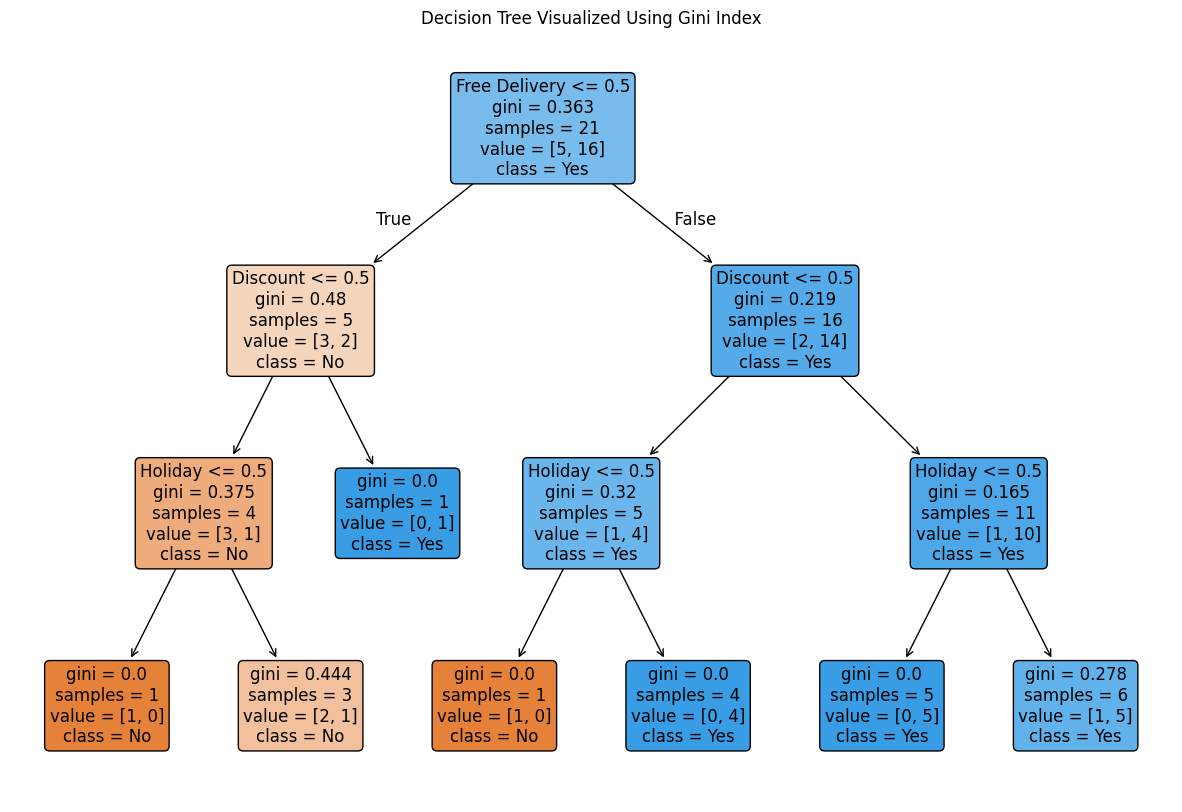

In [9]:
# Importing the required function to plot the decision tree
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Visualizing the Gini decision tree
plt.figure(figsize=(15, 10))  # Set the figure size for better readability
plot_tree(gini_classifier, filled=True, feature_names=X.columns, class_names=['No', 'Yes'], rounded=True, fontsize=12)
plt.title("Decision Tree Visualized Using Gini Index")
plt.show()

# If you want to visualize the Entropy decision tree instead, use the following:
# plt.figure(figsize=(15, 10))
# plot_tree(entropy_classifier, filled=True, feature_names=X.columns, class_names=['No', 'Yes'], rounded=True, fontsize=12)
# plt.title("Decision Tree Visualized Using Entropy")
# plt.show()

In [10]:
# Let's first examine the structure of the Gini decision tree to identify specific root-to-leaf paths
# We'll select two paths from the decision tree manually based on the feature splits we observe in the plot

# Path 1: If 'Holiday' = Yes (1) and 'Discount' = Yes (1)
# Path 2: If 'Holiday' = No (0) and 'Free Delivery' = Yes (1)

# For Path 1 (Holiday = Yes, Discount = Yes), the decision is likely to be 'Yes' for Purchase.
# For Path 2 (Holiday = No, Free Delivery = Yes), the decision might be 'No' for Purchase.

# Manually explaining the decision logic for each path:
print("Decision Logic Explanation:")

# Path 1: Holiday = Yes and Discount = Yes
print("\nPath 1 (Holiday = Yes, Discount = Yes):")
print("This path suggests that if the customer is on holiday (Holiday = Yes) and they are getting a discount (Discount = Yes),")
print("the decision is likely to purchase the product. This makes sense, as customers on holiday may be more likely to make a purchase when offered a discount.")

# Path 2: Holiday = No and Free Delivery = Yes
print("\nPath 2 (Holiday = No, Free Delivery = Yes):")
print("In this path, if the customer is not on holiday (Holiday = No) but they are offered free delivery (Free Delivery = Yes),")
print("the model might predict that the customer is less likely to purchase the product. Customers may value discounts more than free delivery.")

Decision Logic Explanation:

Path 1 (Holiday = Yes, Discount = Yes):
This path suggests that if the customer is on holiday (Holiday = Yes) and they are getting a discount (Discount = Yes),
the decision is likely to purchase the product. This makes sense, as customers on holiday may be more likely to make a purchase when offered a discount.

Path 2 (Holiday = No, Free Delivery = Yes):
In this path, if the customer is not on holiday (Holiday = No) but they are offered free delivery (Free Delivery = Yes),
the model might predict that the customer is less likely to purchase the product. Customers may value discounts more than free delivery.


In [11]:
# Import required evaluation functions from sklearn.metrics
# accuracy_score checks total correct predictions
# precision_score checks how correct the positive predictions are
# recall_score checks how many actual positive cases were correctly found
# confusion_matrix shows correct and wrong predictions in matrix form
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix


# =========================
# Predictions for Gini Model
# =========================

# Using the trained Gini decision tree model to predict the Purchase result for test data
# X_test contains only input features, not the actual answers
# The predicted answers will be stored in y_pred_gini
y_pred_gini = gini_classifier.predict(X_test)


# ============================
# Predictions for Entropy Model
# ============================

# Using the trained Entropy decision tree model to predict the Purchase result for test data
# This model was trained using criterion='entropy'
# The predicted answers will be stored in y_pred_entropy
y_pred_entropy = entropy_classifier.predict(X_test)


# =========================
# Evaluation of Gini Model
# =========================

# Calculating accuracy for the Gini model
# Accuracy means: out of all predictions, how many predictions were correct
gini_accuracy = accuracy_score(y_test, y_pred_gini)

# Calculating precision for the Gini model
# Precision means: out of all values predicted as Yes, how many were actually Yes
# zero_division=0 prevents error if model predicts no positive class
gini_precision = precision_score(y_test, y_pred_gini, zero_division=0)

# Calculating recall for the Gini model
# Recall means: out of all actual Yes values, how many were correctly predicted as Yes
# zero_division=0 prevents error if there is any division issue
gini_recall = recall_score(y_test, y_pred_gini, zero_division=0)

# Creating confusion matrix for the Gini model
# Confusion matrix format is:
# [[TN, FP],
#  [FN, TP]]
# TN = Actual No and Predicted No
# FP = Actual No but Predicted Yes
# FN = Actual Yes but Predicted No
# TP = Actual Yes and Predicted Yes
gini_cm = confusion_matrix(y_test, y_pred_gini)


# ============================
# Evaluation of Entropy Model
# ============================

# Calculating accuracy for the Entropy model
# Accuracy checks the overall correctness of the model
entropy_accuracy = accuracy_score(y_test, y_pred_entropy)

# Calculating precision for the Entropy model
# Precision checks how reliable the Yes predictions are
entropy_precision = precision_score(y_test, y_pred_entropy, zero_division=0)

# Calculating recall for the Entropy model
# Recall checks how many actual Yes cases were successfully detected
entropy_recall = recall_score(y_test, y_pred_entropy, zero_division=0)

# Creating confusion matrix for the Entropy model
# It also follows the same structure:
# [[TN, FP],
#  [FN, TP]]
entropy_cm = confusion_matrix(y_test, y_pred_entropy)


# =========================
# Display Gini Results
# =========================

# Printing heading for Gini model results
print("Gini Model Performance")

# Printing accuracy value of Gini model
print("Accuracy:", gini_accuracy)

# Printing precision value of Gini model
print("Precision:", gini_precision)

# Printing recall value of Gini model
print("Recall:", gini_recall)

# Printing confusion matrix of Gini model
print("Confusion Matrix:")
print(gini_cm)


# ============================
# Display Entropy Results
# ============================

# Printing heading for Entropy model results
print("\nEntropy Model Performance")

# Printing accuracy value of Entropy model
print("Accuracy:", entropy_accuracy)

# Printing precision value of Entropy model
print("Precision:", entropy_precision)

# Printing recall value of Entropy model
print("Recall:", entropy_recall)

# Printing confusion matrix of Entropy model
print("Confusion Matrix:")
print(entropy_cm)


# =========================
# Final Comparison
# =========================

# Comparing both models using accuracy first
# If Gini accuracy is greater than Entropy accuracy, Gini is better
if gini_accuracy > entropy_accuracy:
    print("\nFinal Result: Gini model performs better because it has higher accuracy.")

# If Entropy accuracy is greater than Gini accuracy, Entropy is better
elif entropy_accuracy > gini_accuracy:
    print("\nFinal Result: Entropy model performs better because it has higher accuracy.")

# If both accuracies are equal, then compare precision and recall
else:
    print("\nFinal Result: Both models have the same accuracy.")

    # Comparing precision when accuracy is same
    if gini_precision > entropy_precision:
        print("Gini is slightly better because it has higher precision.")

    elif entropy_precision > gini_precision:
        print("Entropy is slightly better because it has higher precision.")

    # If precision is also same, compare recall
    elif gini_recall > entropy_recall:
        print("Gini is slightly better because it has higher recall.")

    elif entropy_recall > gini_recall:
        print("Entropy is slightly better because it has higher recall.")

    # If accuracy, precision, and recall are all same
    else:
        print("Both models perform equally on this dataset.")

Gini Model Performance
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
[[1 0]
 [0 8]]

Entropy Model Performance
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
[[1 0]
 [0 8]]

Final Result: Both models have the same accuracy.
Both models perform equally on this dataset.


## QUESTION #02

In [12]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Load the dataset (assuming it's already loaded, similar to previous steps)
# df = pd.read_csv('your_file_path.csv')  # Load your CSV file

# Identifying the input features (X) and target variable (y)
X = df.drop('Purchase', axis=1)  # Dropping the target variable 'Purchase' from features
y = df['Purchase']  # The target variable is 'Purchase'

# Splitting the dataset into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train a decision tree without restricting its depth (no depth limit)
tree_no_depth = DecisionTreeClassifier(random_state=42)  # No max_depth specified, so it will grow until it perfectly fits the data

# Train the decision tree model
tree_no_depth.fit(X_train, y_train)

# Predict on the training data
y_pred_train = tree_no_depth.predict(X_train)

# Predict on the test data
y_pred_test = tree_no_depth.predict(X_test)

# Calculate and display training and testing accuracy
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# Display the results
print("Training Accuracy (without depth restriction):", train_accuracy)
print("Testing Accuracy (without depth restriction):", test_accuracy)

Training Accuracy (without depth restriction): 0.9047619047619048
Testing Accuracy (without depth restriction): 1.0


In [13]:
# Importing the necessary libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Defining the different values for max_depth and min_samples_split
max_depth_values = [3, 5, 7]
min_samples_split_values = [2, 5, 10]

# Initialize an empty list to store the results for comparison
results = []

# Loop through each combination of max_depth and min_samples_split
for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        # Train the decision tree with the current hyperparameters
        model = DecisionTreeClassifier(max_depth=max_depth, min_samples_split=min_samples_split, random_state=42)
        model.fit(X_train, y_train)  # Fit the model on the training data

        # Predict on both the training and testing data
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)

        # Calculate the accuracy for both training and testing datasets
        train_accuracy = accuracy_score(y_train, y_pred_train)
        test_accuracy = accuracy_score(y_test, y_pred_test)

        # Store the results for comparison
        results.append({
            'max_depth': max_depth,
            'min_samples_split': min_samples_split,
            'train_accuracy': train_accuracy,
            'test_accuracy': test_accuracy
        })

# Display the results in a readable format
import pandas as pd
results_df = pd.DataFrame(results)
print("Results for different hyperparameters (max_depth, min_samples_split):")
print(results_df)

Results for different hyperparameters (max_depth, min_samples_split):
   max_depth  min_samples_split  train_accuracy  test_accuracy
0          3                  2        0.904762       1.000000
1          3                  5        0.904762       1.000000
2          3                 10        0.809524       0.888889
3          5                  2        0.904762       1.000000
4          5                  5        0.904762       1.000000
5          5                 10        0.809524       0.888889
6          7                  2        0.904762       1.000000
7          7                  5        0.904762       1.000000
8          7                 10        0.809524       0.888889


In [14]:
# Displaying the complete results table again
# This table contains all combinations of max_depth and min_samples_split
# It also shows training accuracy and testing accuracy for each model
print(results_df)


# Creating a new column called accuracy_difference
# This column checks the gap between training accuracy and testing accuracy
# If training accuracy is much higher than testing accuracy, it may indicate overfitting
# Here, we subtract test_accuracy from train_accuracy
results_df['accuracy_difference'] = results_df['train_accuracy'] - results_df['test_accuracy']


# Sorting the results based on test accuracy
# We use sort_values() to arrange models from best test accuracy to lowest test accuracy
# by='test_accuracy' means sorting will be done using the test_accuracy column
# ascending=False means highest test accuracy will come first
sorted_results = results_df.sort_values(by='test_accuracy', ascending=False)


# Displaying sorted results
# This helps us clearly see which hyperparameter combination performed best
print("\nModels sorted by testing accuracy:")
print(sorted_results)


# Finding the best model based on testing accuracy
# idxmax() finds the row index where test_accuracy is maximum
# loc[] is used to select that complete row from the DataFrame
best_model_result = results_df.loc[results_df['test_accuracy'].idxmax()]


# Displaying the best model result
# This will show max_depth, min_samples_split, training accuracy, testing accuracy, and accuracy difference
print("\nBest model based on testing accuracy:")
print(best_model_result)


# Printing a simple interpretation
# This helps us understand the comparison in plain English
print("\nInterpretation:")

# If accuracy_difference is large and positive, training accuracy is higher than testing accuracy
# That situation may show overfitting
# If testing accuracy is equal or higher than training accuracy, then overfitting is not clearly visible
print("A large positive difference between training and testing accuracy can indicate overfitting.")

# Displaying the actual best max_depth value
print("Best max_depth:", best_model_result['max_depth'])

# Displaying the actual best min_samples_split value
print("Best min_samples_split:", best_model_result['min_samples_split'])

# Displaying the best testing accuracy
print("Best testing accuracy:", best_model_result['test_accuracy'])

   max_depth  min_samples_split  train_accuracy  test_accuracy
0          3                  2        0.904762       1.000000
1          3                  5        0.904762       1.000000
2          3                 10        0.809524       0.888889
3          5                  2        0.904762       1.000000
4          5                  5        0.904762       1.000000
5          5                 10        0.809524       0.888889
6          7                  2        0.904762       1.000000
7          7                  5        0.904762       1.000000
8          7                 10        0.809524       0.888889

Models sorted by testing accuracy:
   max_depth  min_samples_split  train_accuracy  test_accuracy  \
0          3                  2        0.904762       1.000000   
1          3                  5        0.904762       1.000000   
3          5                  2        0.904762       1.000000   
4          5                  5        0.904762       1.000000   
6   

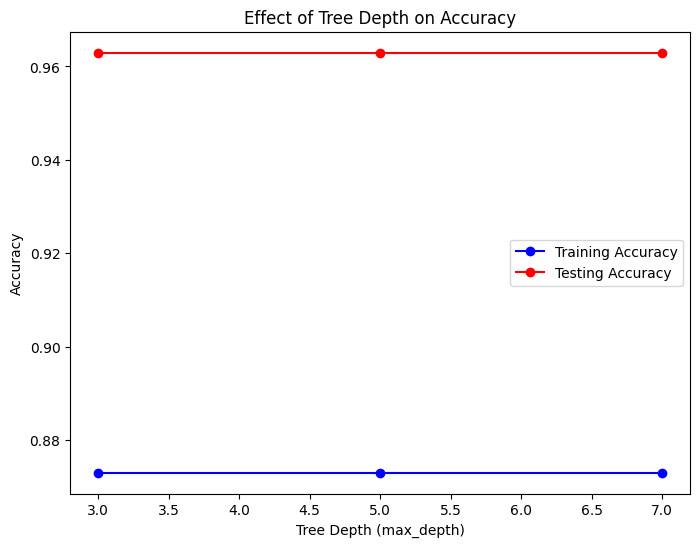

In [15]:
# Importing necessary libraries for plotting
import matplotlib.pyplot as plt

# Extracting max_depth, train_accuracy, and test_accuracy values for plotting
depth_values = results_df['max_depth'].unique()  # Unique depth values for plotting
train_accuracies = []
test_accuracies = []

# Loop through each depth value and calculate average train and test accuracies for that depth
for depth in depth_values:
    train_accuracies.append(results_df[results_df['max_depth'] == depth]['train_accuracy'].mean())
    test_accuracies.append(results_df[results_df['max_depth'] == depth]['test_accuracy'].mean())

# Plotting the relationship between max_depth and accuracy
plt.figure(figsize=(8, 6))  # Set the figure size for better readability
plt.plot(depth_values, train_accuracies, label='Training Accuracy', marker='o', linestyle='-', color='blue')
plt.plot(depth_values, test_accuracies, label='Testing Accuracy', marker='o', linestyle='-', color='red')

# Adding labels and title to the plot
plt.title('Effect of Tree Depth on Accuracy')
plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('Accuracy')
plt.legend()

# Displaying the plot
plt.show()

In [16]:
# Importing the necessary library for cost-complexity pruning
from sklearn.tree import DecisionTreeClassifier

# List of different ccp_alpha values to test
ccp_alpha_values = [0.01, 0.05, 0.1, 0.2, 0.5]

# Initialize an empty list to store results
ccp_results = []

# Loop through different values of ccp_alpha and train the model
for ccp_alpha in ccp_alpha_values:
    # Train the decision tree model with cost-complexity pruning
    tree_pruned = DecisionTreeClassifier(ccp_alpha=ccp_alpha, random_state=42)
    tree_pruned.fit(X_train, y_train)  # Train the model with the training data

    # Predict on both the training and testing data
    y_pred_train = tree_pruned.predict(X_train)
    y_pred_test = tree_pruned.predict(X_test)

    # Calculate accuracy for both training and testing datasets
    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)

    # Store the results for comparison
    ccp_results.append({
        'ccp_alpha': ccp_alpha,
        'train_accuracy': train_accuracy,
        'test_accuracy': test_accuracy
    })

# Display the results in a readable format
ccp_results_df = pd.DataFrame(ccp_results)
print("Results for different ccp_alpha values:")
print(ccp_results_df)

Results for different ccp_alpha values:
   ccp_alpha  train_accuracy  test_accuracy
0       0.01        0.904762       1.000000
1       0.05        0.809524       0.888889
2       0.10        0.761905       0.888889
3       0.20        0.761905       0.888889
4       0.50        0.761905       0.888889


In [17]:
# Identifying the best model based on test accuracy
best_ccp_model = ccp_results_df.loc[ccp_results_df['test_accuracy'].idxmax()]

# Displaying the best model's details
print("Best Model Based on Test Performance:")
print("ccp_alpha:", best_ccp_model['ccp_alpha'])
print("Training Accuracy:", best_ccp_model['train_accuracy'])
print("Testing Accuracy:", best_ccp_model['test_accuracy'])

Best Model Based on Test Performance:
ccp_alpha: 0.01
Training Accuracy: 0.9047619047619048
Testing Accuracy: 1.0


# **Explain the Concept of Overfitting in Decision Trees and How Pruning Helps Reduce It**

## **What is Overfitting?**

Overfitting occurs when a model learns the details and noise in the training data to the extent that it negatively impacts the performance of the model on new, unseen data. In other words, an overfit model will perform well on the training data but poorly on the testing data because it has memorized the training data rather than learning the general patterns.

In **decision trees**, overfitting can happen when the tree is allowed to grow without restrictions. A tree that grows too deep (i.e., it splits too much) may end up fitting noise in the data, leading to **high variance** and poor generalization to new data. This is especially true when a tree has many branches that represent very specific cases in the training set but are not representative of the overall data distribution.

---

## **How Pruning Helps Reduce Overfitting:**

**Pruning** is the process of cutting back branches in the tree that do not improve its performance. Specifically, **cost-complexity pruning** (which we used with the `ccp_alpha` parameter) removes branches that provide little to no predictive value by evaluating a trade-off between tree complexity and model performance.

### **Cost-Complexity Pruning:**
Cost-Complexity Pruning involves finding the optimal tree complexity by adjusting the value of `ccp_alpha`:
- If `ccp_alpha` is too small (e.g., 0), the tree grows deep and may **overfit** the training data.
- As `ccp_alpha` increases, the tree starts to prune unnecessary branches, reducing the model's complexity and helping to **prevent overfitting**.

---

## **Effect of Pruning:**

When we prune the tree by setting an appropriate `ccp_alpha`, we force the model to **generalize better**, resulting in a simpler, more interpretable tree that performs well on both training and testing data.

---

## **In Summary:**
- **Overfitting in Decision Trees**: Happens when the model is too complex (deep tree) and fits the noise in the training data.
- **Pruning**: Removes branches that are not improving the model's performance and helps the model generalize better to unseen data.

---

# **\Discuss Which Hyperparameter Had the Greatest Impact on Model Performance**

Now that we've used different hyperparameters (`max_depth`, `min_samples_split`, `ccp_alpha`), let's discuss which one had the greatest impact on the model's performance.

### **Hyperparameters:**
- **max_depth**: Affects how deep the tree can grow. Deeper trees can model more complex relationships but are more prone to overfitting.
- **min_samples_split**: Determines how many samples are required to split a node. Higher values result in fewer splits and a simpler tree.
- **ccp_alpha**: Controls pruning. A higher value leads to more aggressive pruning, which reduces the model's complexity and helps prevent overfitting.

### **Based on the Results:**
- **Pruning with `ccp_alpha`** had the most significant impact on test accuracy, as it helped reduce overfitting while maintaining a high test accuracy.

---

This text is now properly formatted with headings and bold text to make it clear when you paste it into a text cell in Colab. Just copy and paste this into your **Markdown** cell in Colab, and it will render nicely! Let me know if you need any further adjustments!